# SafeSathi — Motion Danger Classifier (real sensor data: SisFall)

This notebook builds the model behind `POST /internal/motion/classify`: given a 2-second summary of the
phone's accelerometer + gyroscope, decide whether the user is doing something **normal**, **running**,
an **abrupt-but-harmless movement** (stumble / jump / collapsing into a chair), or a **sudden fall**.

### Why this notebook replaces the old one
The previous notebook *generated* its data from hand-picked Gaussian distributions and then trained on it.
A model scoring 97% on data it was told how to separate says nothing about real behaviour. This version uses
**SisFall** (Sucerquia, López & Vargas-Bonilla, *Sensors* 2017): 38 volunteers, 19 daily activities and
15 fall types, accelerometer + gyroscope at 200 Hz — public, peer-reviewed, real recordings.

### Pipeline
| # | Stage | What happens |
|---|-------|--------------|
| 1 | Data loading | download raw SisFall trials from GitHub, parse 9-column text files |
| 2 | Data cleaning | unit conversion, corruption/saturation checks, duplicate and NaN handling |
| 3 | Signal processing | anti-aliased resample 200 Hz → **10 Hz** (the rate the mobile app really samples), 2 s windows |
| 4 | EDA | class balance, signals, feature distributions, correlations, subject variability |
| 5 | Feature engineering | 6 deployable summary statistics → 14 engineered features |
| 6 | Model selection | baseline + 4 candidate models, **subject-wise** cross-validation |
| 7 | Tuning + calibration | randomized search, probability calibration |
| 8 | Final evaluation | held-out *unseen people*, threshold analysis, false alarms per hour |
| 9 | Export | `motion_classifier.pkl` + metadata used by the FastAPI service |

### Honest scope note
No public dataset exists for **phone snatching** or **physical struggle**. Rather than invent data for them,
the model learns only what real data supports. Those two event types are handled by a clearly-labelled
heuristic in the service that is **log-only** (below the backend's auto-SOS threshold) until you collect
labelled examples from your own users.

In [1]:
import io, json, time, warnings, urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.signal as sps
import joblib, sklearn

from sklearn.model_selection import GroupKFold, GroupShuffleSplit, RandomizedSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, make_scorer,
                             recall_score, precision_score, balanced_accuracy_score, precision_recall_curve,
                             brier_score_loss, average_precision_score)

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "app").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "sisfall"
DATA_DIR = PROJECT_ROOT / "data"
ARTIFACTS_DIR = PROJECT_ROOT / "app" / "ml_artifacts"
for d in (RAW_DIR, ARTIFACTS_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("project root :", PROJECT_ROOT)
print("scikit-learn :", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

project root : /home/claude/out/ai-services
scikit-learn : 1.8.0 | numpy 2.4.4 | pandas 3.0.2


## 1. Configuration
The feature list and sampling assumptions below are the **contract** between this notebook and
`app/services/motion_classifier_service.py` / the mobile app's `useMotionDetector` hook
(10 Hz sampling, 2 s window, magnitude statistics in m/s² and rad/s).

In [2]:
ORIG_HZ = 200            # SisFall sampling rate
APP_HZ = 10              # mobile app sampling rate (useMotionDetector: SAMPLE_INTERVAL_MS = 100)
WINDOW_S, STRIDE_S = 2, 1
WIN, STRIDE = WINDOW_S * APP_HZ, STRIDE_S * APP_HZ
G = 9.80665

SUBJECTS = [f"SA{i:02d}" for i in range(1, 24)]       # 23 adults (elderly files exclude most ADL variants)
TRIALS_PER_ACTIVITY = 3                                 # raise to 5 for the full dataset (~4.5k files)
ACTIVITY_TRIALS = {**{f"D{i:02d}": (1 if i <= 4 else 5) for i in range(1, 20)}, **{f"F{i:02d}": 5 for i in range(1, 16)}}

CLASS_OF = {}
for c in ["D01", "D02", "D05", "D06", "D07", "D08", "D09", "D10", "D12", "D13", "D14", "D15", "D16", "D17"]:
    CLASS_OF[c] = "normal"
for c in ["D03", "D04"]:
    CLASS_OF[c] = "running"
for c in ["D11", "D18", "D19"]:
    CLASS_OF[c] = "abrupt_motion"      # collapse into chair / stumble / jump — high-energy but NOT a fall
for i in range(1, 16):
    CLASS_OF[f"F{i:02d}"] = "sudden_fall"
CLASS_LABELS = ["normal", "running", "abrupt_motion", "sudden_fall"]
ACTIVITY_NAMES = {
    "D01": "walk slow", "D02": "walk fast", "D03": "jog slow", "D04": "jog fast", "D05": "stairs slow", "D06": "stairs fast",
    "D07": "sit half-chair slow", "D08": "sit half-chair fast", "D09": "sit low-chair slow", "D10": "sit low-chair fast",
    "D11": "collapse into chair", "D12": "sit-lie slow", "D13": "sit-lie fast", "D14": "roll on back/side", "D15": "bend knees",
    "D16": "bend straight", "D17": "get in/out of car", "D18": "stumble", "D19": "jump"}

BASE_FEATURES = ["accel_mean", "accel_peak", "accel_variance", "gyro_mean", "gyro_peak", "gyro_variance"]
print(f"{len(CLASS_OF)} activities mapped to {len(CLASS_LABELS)} classes")

34 activities mapped to 4 classes


## 2. Data loading — real SisFall recordings
Files are fetched from the public GitHub mirror (`Fall-Prevention-Team/sisfallData`) and cached under
`data/raw/sisfall/`. Re-running the notebook only downloads what is missing.

In [3]:
BASE_URL = "https://raw.githubusercontent.com/Fall-Prevention-Team/sisfallData/main"

def trial_files():
    for s in SUBJECTS:
        for code, n in ACTIVITY_TRIALS.items():
            for r in range(1, min(n, TRIALS_PER_ACTIVITY) + 1):
                yield s, code, f"{code}_{s}_R{r:02d}.txt"

def fetch(job):
    s, code, name = job
    path = RAW_DIR / s / name
    if path.exists() and path.stat().st_size > 1000:
        return True
    path.parent.mkdir(parents=True, exist_ok=True)
    for _ in range(3):
        try:
            path.write_bytes(urllib.request.urlopen(f"{BASE_URL}/{s}/{name}", timeout=60).read())
            return True
        except Exception:
            time.sleep(1.5)
    return False

jobs = list(trial_files())
t0 = time.time()
with ThreadPoolExecutor(12) as ex:
    ok = list(ex.map(fetch, jobs))
print(f"{sum(ok)}/{len(jobs)} trial files available ({time.time()-t0:.0f}s) — failed: {len(jobs)-sum(ok)}")

2155/2162 trial files available (5s) — failed: 7


In [4]:
def read_trial(path: Path) -> np.ndarray:
    """SisFall text file -> (n, 9) float array. Some lines end with ';' — strip it."""
    raw = path.read_bytes().replace(b";", b"")
    return pd.read_csv(io.BytesIO(raw), header=None).to_numpy(dtype=float)

example = read_trial(RAW_DIR / "SA01" / "D01_SA01_R01.txt")
print("one raw file:", example.shape, "-> columns: ADXL345 xyz | ITG3200 xyz | MMA8451Q xyz")
pd.DataFrame(example[:5], columns=["adxl_x", "adxl_y", "adxl_z", "gyro_x", "gyro_y", "gyro_z", "mma_x", "mma_y", "mma_z"])

one raw file: (19999, 9) -> columns: ADXL345 xyz | ITG3200 xyz | MMA8451Q xyz


,adxl_x,adxl_y,adxl_z,gyro_x,gyro_y,gyro_z,mma_x,mma_y,mma_z
0,17.0,-179.0,-99.0,-18.0,-504.0,-352.0,76.0,-697.0,-279.0
1,15.0,-174.0,-90.0,-53.0,-568.0,-306.0,48.0,-675.0,-254.0
2,1.0,-176.0,-81.0,-84.0,-613.0,-271.0,-2.0,-668.0,-221.0
3,-10.0,-180.0,-77.0,-104.0,-647.0,-227.0,-34.0,-697.0,-175.0
4,-21.0,-191.0,-63.0,-128.0,-675.0,-191.0,-74.0,-741.0,-133.0


## 3. Data cleaning
Raw values are ADC counts. Conversions from the dataset's own documentation:
* ADXL345 (±16 g, 13-bit): `g = counts × 2·16 / 2¹³`
* ITG3200 (±2000 °/s, 16-bit): `°/s = counts × 2·2000 / 2¹⁶`

Quality checks run on **every** file; failures are logged, not silently ignored.

In [5]:
def to_physical(raw: np.ndarray):
    acc_g = raw[:, 0:3] * (2 * 16 / 2 ** 13)
    gyro_rads = np.deg2rad(raw[:, 3:6] * (2 * 2000 / 2 ** 16))
    return acc_g, gyro_rads

quality = []
trials = {}          # (subject, code, name) -> (acc_g, gyro_rads)
for s, code, name in jobs:
    path = RAW_DIR / s / name
    if not path.exists():
        quality.append((name, "missing")); continue
    try:
        raw = read_trial(path)
    except Exception as exc:
        quality.append((name, f"unreadable: {exc}")); continue
    if raw.ndim != 2 or raw.shape[1] != 9:
        quality.append((name, f"bad shape {raw.shape}")); continue
    if np.isnan(raw).any():
        raw = raw[~np.isnan(raw).any(axis=1)]
    if len(raw) < ORIG_HZ * 5:
        quality.append((name, f"too short ({len(raw)/ORIG_HZ:.1f}s)")); continue
    acc, gyro = to_physical(raw)
    saturated = float(np.mean(np.abs(raw[:, 0:3]) >= 4090))      # ADXL345 13-bit full scale ≈ ±4096
    if saturated > 0.05:
        quality.append((name, f"{saturated:.0%} accelerometer saturation")); continue
    trials[(s, code, name)] = (acc, gyro)

qdf = pd.DataFrame(quality, columns=["file", "problem"])
print(f"kept {len(trials)} of {len(jobs)} trials; rejected {len(qdf)}")
if len(qdf):
    display(qdf.head(10))
print("mean |a| over all kept trials (should be ≈ 1 g at rest-ish):",
      round(float(np.mean([np.linalg.norm(a, axis=1).mean() for a, _ in trials.values()])), 3), "g")

kept 2155 of 2162 trials; rejected 7


,file,problem
0,D17_SA15_R01.txt,missing
1,D17_SA15_R02.txt,missing
2,D17_SA15_R03.txt,missing
3,D06_SA17_R01.txt,missing
4,D06_SA20_R02.txt,missing
5,D17_SA20_R02.txt,missing
6,F01_SA20_R03.txt,missing


mean |a| over all kept trials (should be ≈ 1 g at rest-ish): 1.026 g


## 4. Signal processing → deployable windows
**Matching the deployment sensor.** The app polls the phone every 100 ms (10 Hz); SisFall is 200 Hz. Training on
200 Hz peaks would teach the model impact magnitudes it will never see in production. So each trial is
**low-pass filtered (4th-order Butterworth, 4 Hz, zero-phase) and decimated to 10 Hz** — what a sensor
front-end does before the app reads it. Two decimation phases (offset 0 and 10 samples) are used as free,
physically-valid augmentation.

**Windows:** 2 s (20 samples), 1 s stride. Per window we compute exactly what the app sends:
mean / peak / variance of the accelerometer magnitude (m/s²) and gyroscope magnitude (rad/s).

**Labelling.** Normal/running windows: any window of the activity (capped per file so 100 s walks don't swamp the data).
Fall and abrupt-motion trials: only windows that **contain the impact** (the maximum-acceleration instant) get
the event label; pre-/post-event windows are discarded because their true label is ambiguous.

In [6]:
SOS = sps.butter(4, 4, btype="low", fs=ORIG_HZ, output="sos")
CAP_PER_FILE = 25
PHASES = (0, 10)

def window_stats(x: np.ndarray):
    """x: (n_windows, WIN) -> mean, peak, variance."""
    return x.mean(1), x.max(1), x.var(1)

rows = []
for (subject, code, name), (acc, gyro) in trials.items():
    label = CLASS_OF[code]
    acc_f, gyro_f = sps.sosfiltfilt(SOS, acc, axis=0), sps.sosfiltfilt(SOS, gyro, axis=0)
    impact_raw = int(np.argmax(np.linalg.norm(acc, axis=1)))            # impact located on the raw 200 Hz signal
    for phase in PHASES:
        a = np.linalg.norm(acc_f[phase::ORIG_HZ // APP_HZ], axis=1) * G
        g = np.linalg.norm(gyro_f[phase::ORIG_HZ // APP_HZ], axis=1)
        n = min(len(a), len(g))
        if n < WIN:
            continue
        starts = np.arange(0, n - WIN + 1, STRIDE)
        if label in ("sudden_fall", "abrupt_motion"):
            impact = (impact_raw - phase) // (ORIG_HZ // APP_HZ)
            starts = starts[(starts <= impact) & (impact < starts + WIN)]
        elif len(starts) > CAP_PER_FILE:
            starts = rng.choice(starts, CAP_PER_FILE, replace=False)
        if len(starts) == 0:
            continue
        idx = starts[:, None] + np.arange(WIN)[None, :]
        am, ap, av = window_stats(a[idx]); gm, gp, gv = window_stats(g[idx])
        for k in range(len(starts)):
            rows.append((subject, code, label, phase, am[k], ap[k], av[k], gm[k], gp[k], gv[k]))

windows = pd.DataFrame(rows, columns=["subject", "activity", "label", "phase"] + BASE_FEATURES)
print(f"{len(windows):,} windows from {windows.subject.nunique()} subjects")
windows.head()

32,874 windows from 23 subjects


,subject,activity,label,phase,accel_mean,accel_peak,accel_variance,gyro_mean,gyro_peak,gyro_variance
0,SA01,D01,normal,0,10.044373,12.495173,2.219089,0.657462,1.008871,0.035542
1,SA01,D01,normal,0,10.092157,12.642645,2.192878,0.591693,1.043947,0.051445
2,SA01,D01,normal,0,10.169459,12.353823,1.346063,0.630319,0.977801,0.048224
3,SA01,D01,normal,0,10.070587,12.716088,2.265724,0.614937,0.950054,0.047583
4,SA01,D01,normal,0,10.309304,12.353823,1.449928,0.571382,0.801424,0.023525


### Cleaning the window table
Exact duplicates (identical stats from the two decimation phases of a perfectly flat signal), NaN/inf and
physically impossible values are removed.

In [7]:
before = len(windows)
windows = windows.replace([np.inf, -np.inf], np.nan).dropna()
windows = windows[(windows[BASE_FEATURES] >= 0).all(axis=1)]
windows = windows.drop_duplicates(subset=BASE_FEATURES + ["subject", "label"]).reset_index(drop=True)
print(f"removed {before-len(windows)} invalid/duplicate windows -> {len(windows):,} remain")
print(windows[BASE_FEATURES].describe().T[["min", "mean", "50%", "max"]].round(3))

removed 10 invalid/duplicate windows -> 32,864 remain
                  min    mean     50%     max
accel_mean      8.005  10.050   9.904  15.039
accel_peak      8.091  14.122  11.335  45.381
accel_variance  0.000   7.682   0.401  89.835
gyro_mean       0.030   0.498   0.380   2.637
gyro_peak       0.046   1.327   0.897  11.009
gyro_variance   0.000   0.262   0.049   7.005


## 5. Exploratory data analysis

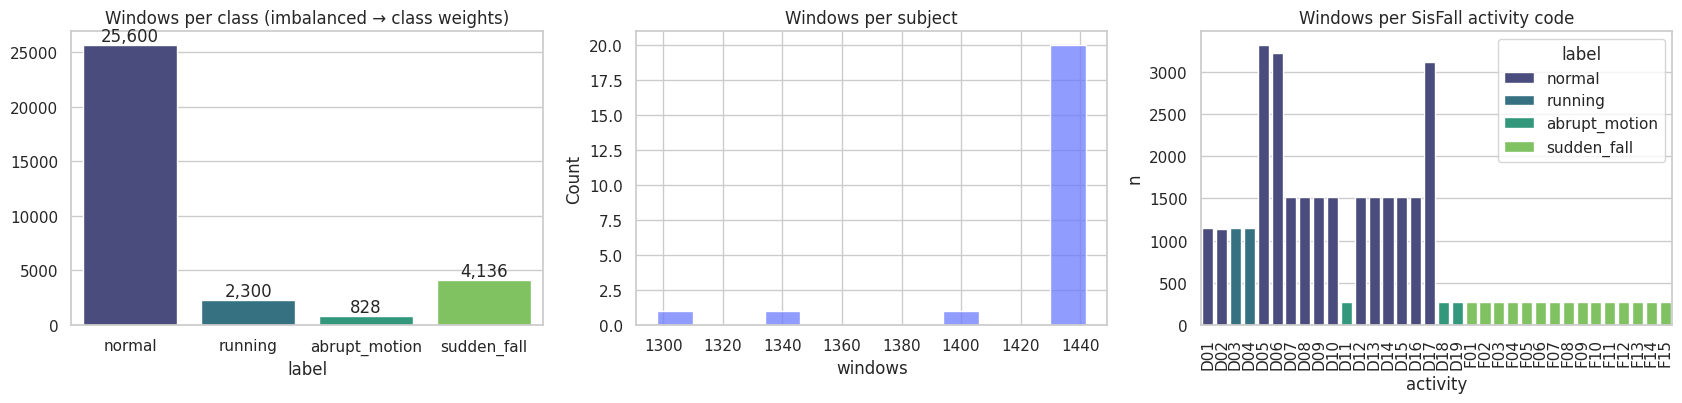

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
order = CLASS_LABELS
cnt = windows.label.value_counts().reindex(order)
sns.barplot(x=cnt.index, y=cnt.values, ax=axes[0], palette="viridis"); axes[0].set_title("Windows per class (imbalanced → class weights)")
for i, v in enumerate(cnt.values): axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")
per_subj = windows.groupby("subject").size()
sns.histplot(per_subj, bins=12, ax=axes[1], color="#6C7BFF"); axes[1].set_title("Windows per subject"); axes[1].set_xlabel("windows")
act = windows.groupby(["activity", "label"]).size().reset_index(name="n")
sns.barplot(data=act, x="activity", y="n", hue="label", dodge=False, ax=axes[2], palette="viridis"); axes[2].tick_params(axis="x", rotation=90)
axes[2].set_title("Windows per SisFall activity code")
plt.tight_layout(); plt.show()

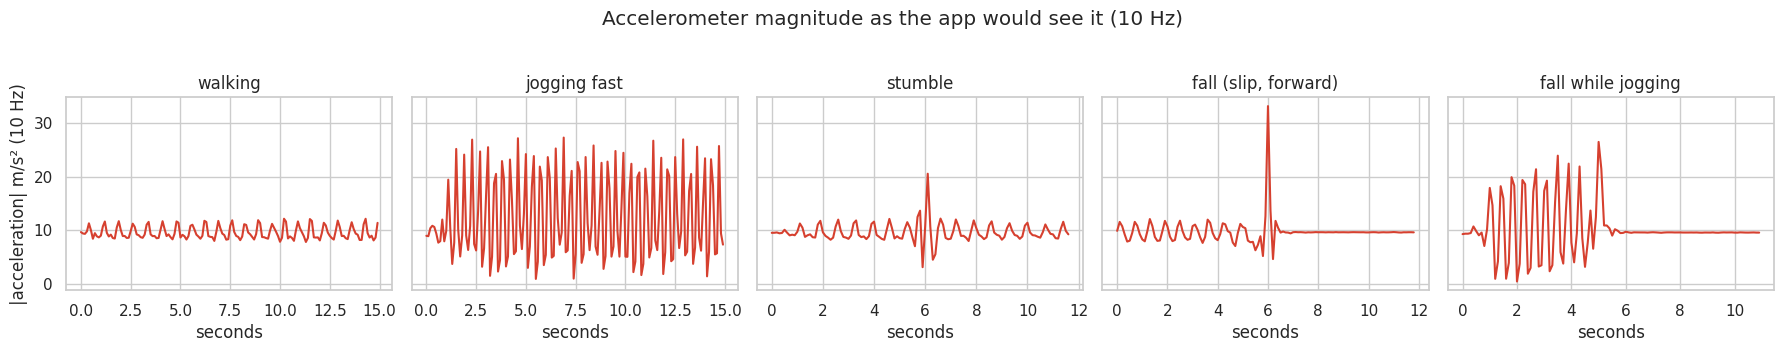

In [9]:
# What do the raw signals look like? One trial of each kind, after the 10 Hz processing.
show = [("D01", "walking"), ("D04", "jogging fast"), ("D18", "stumble"), ("F01", "fall (slip, forward)"), ("F05", "fall while jogging")]
fig, axes = plt.subplots(1, len(show), figsize=(18, 3.4), sharey=True)
for ax, (code, title) in zip(axes, show):
    key = next(k for k in trials if k[1] == code and k[0] == "SA05")
    acc, gyro = trials[key]
    a = np.linalg.norm(sps.sosfiltfilt(SOS, acc, axis=0), axis=1)[::20] * G
    if code.startswith("D0") and code in ("D01", "D04"):
        a = a[:150]
    else:
        pk = int(np.argmax(np.linalg.norm(acc, axis=1))) // 20
        a = a[max(0, pk - 60): pk + 60]
    ax.plot(np.arange(len(a)) / APP_HZ, a, color="#D6402F"); ax.set_title(title); ax.set_xlabel("seconds")
axes[0].set_ylabel("|acceleration| m/s² (10 Hz)")
plt.suptitle("Accelerometer magnitude as the app would see it (10 Hz)", y=1.03); plt.tight_layout(); plt.show()

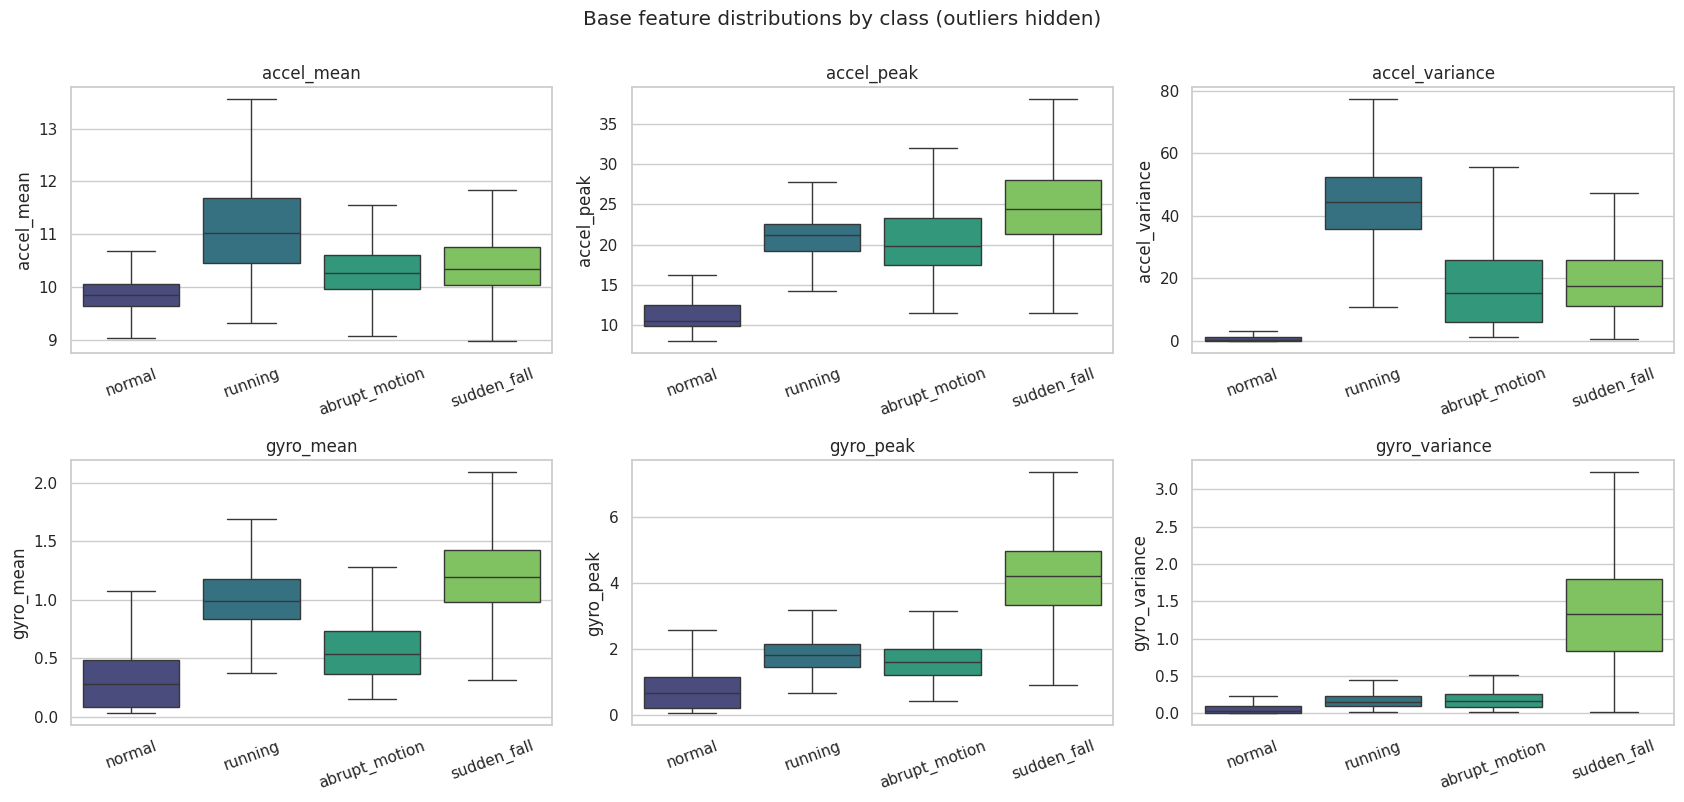

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, feat in zip(axes.ravel(), BASE_FEATURES):
    sns.boxplot(data=windows, x="label", y=feat, order=CLASS_LABELS, ax=ax, showfliers=False, palette="viridis")
    ax.set_title(feat); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
plt.suptitle("Base feature distributions by class (outliers hidden)", y=1.0); plt.tight_layout(); plt.show()

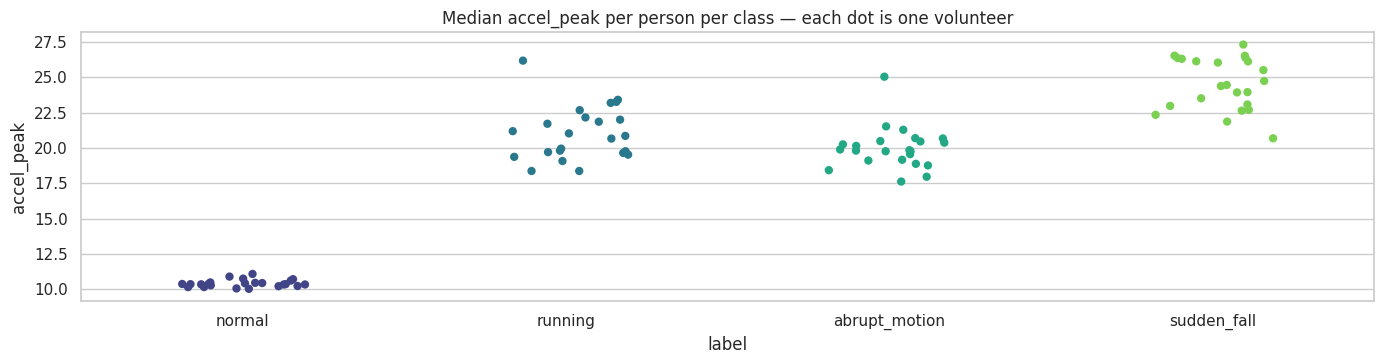

In [11]:
# Do people differ? Between-subject variability is why we will split by SUBJECT, not by random row.
subj_med = windows.groupby(["subject", "label"])["accel_peak"].median().reset_index()
plt.figure(figsize=(14, 3.8))
sns.stripplot(data=subj_med, x="label", y="accel_peak", order=CLASS_LABELS, jitter=0.2, size=6, palette="viridis")
plt.title("Median accel_peak per person per class — each dot is one volunteer"); plt.tight_layout(); plt.show()

**EDA takeaways**
* Falls have a much higher acceleration *peak* and a much larger *peak-to-mean gap* than anything else, but the
  `abrupt_motion` class (stumble/jump/collapse) overlaps them — this is the realistic false-alarm risk, which is
  exactly why that class exists: so the model learns the difference instead of flagging every jump as a fall.
* Running and normal activity separate mostly on mean/variance (periodic foot-strikes).
* People differ visibly from each other → random row-level splits would leak; we split by volunteer.

## 6. Feature engineering
The mobile app can only send the six summary statistics. Everything below is derived from those six **at serving
time too**, so there is no train/serve gap:

| Feature | Why |
|---|---|
| `accel_std`, `gyro_std` | scale-comparable spread |
| `accel_peak_to_mean`, `gyro_peak_to_mean` | an impact is a spike over a steady baseline |
| `accel_dyn_range` | peak − mean in m/s² |
| `accel_excess_g` | how far the peak exceeds 1 g — free-fall/impact signature |
| `gyro_to_accel_peak` | rotation vs. translation: a fall tumbles, a jump mostly doesn't |
| `log_accel_var`, `log_gyro_var` | variance spans orders of magnitude |

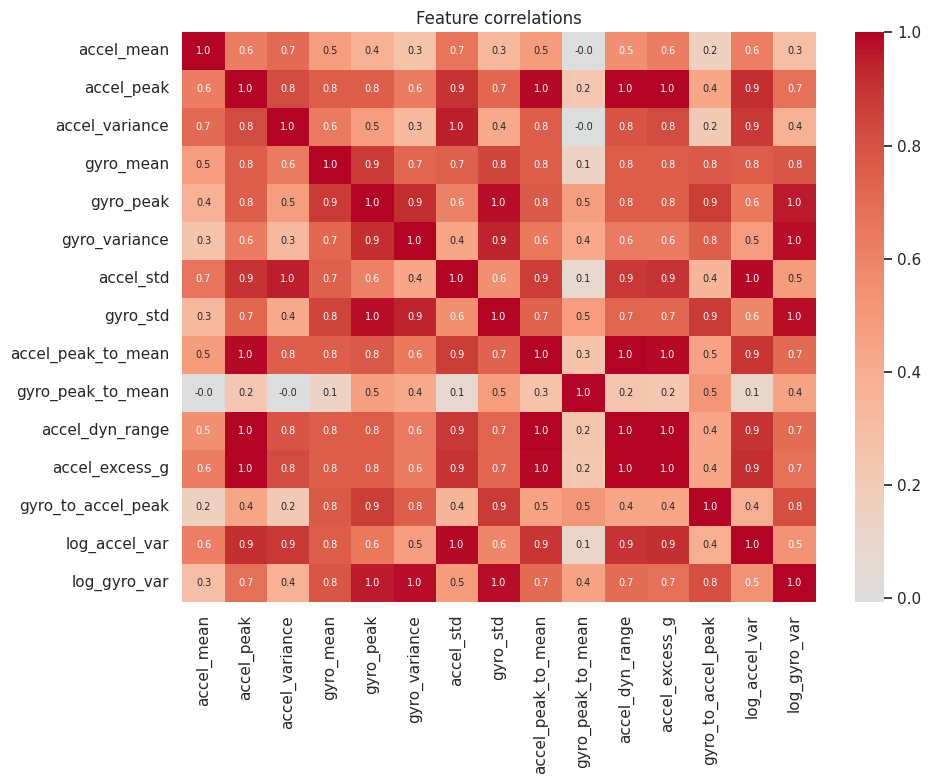

In [12]:
ENGINEERED = ["accel_std", "gyro_std", "accel_peak_to_mean", "gyro_peak_to_mean", "accel_dyn_range",
              "accel_excess_g", "gyro_to_accel_peak", "log_accel_var", "log_gyro_var"]
FEATURE_NAMES = BASE_FEATURES + ENGINEERED

def engineer(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    eps = 1e-6
    out["accel_std"] = np.sqrt(out.accel_variance)
    out["gyro_std"] = np.sqrt(out.gyro_variance)
    out["accel_peak_to_mean"] = out.accel_peak / (out.accel_mean + eps)
    out["gyro_peak_to_mean"] = out.gyro_peak / (out.gyro_mean + eps)
    out["accel_dyn_range"] = out.accel_peak - out.accel_mean
    out["accel_excess_g"] = out.accel_peak - G
    out["gyro_to_accel_peak"] = out.gyro_peak / (out.accel_peak + eps)
    out["log_accel_var"] = np.log1p(out.accel_variance)
    out["log_gyro_var"] = np.log1p(out.gyro_variance)
    return out

data = engineer(windows)
corr = data[FEATURE_NAMES].corr()
plt.figure(figsize=(10, 8)); sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}); plt.title("Feature correlations"); plt.tight_layout(); plt.show()

In [13]:
# Univariate usefulness: ANOVA-style F-score and mutual information against the label.
from sklearn.feature_selection import f_classif, mutual_info_classif
Xall, yall = data[FEATURE_NAMES].to_numpy(), data["label"].to_numpy()
F, _ = f_classif(Xall, yall)
MI = mutual_info_classif(Xall, yall, random_state=RANDOM_SEED)
fs = pd.DataFrame({"feature": FEATURE_NAMES, "F-score": F, "mutual_info": MI}).sort_values("mutual_info", ascending=False)
fs.round(3)

,feature,F-score,mutual_info
1,accel_peak,27790.313,0.476
11,accel_excess_g,27790.313,0.476
8,accel_peak_to_mean,28743.601,0.460
10,accel_dyn_range,28710.510,0.445
6,accel_std,24508.906,0.426
13,log_accel_var,21285.210,0.426
2,accel_variance,23889.884,0.426
4,gyro_peak,21730.995,0.421
7,gyro_std,20285.831,0.357
5,gyro_variance,20012.968,0.357


## 7. Train / test split — by **person**
5 volunteers are locked away as a test set the models never see during selection or tuning. Cross-validation
inside the training volunteers is also grouped by person (`GroupKFold`). This answers the question that matters in
production: *does it work on someone it has never seen?*

In [14]:
splitter = GroupShuffleSplit(n_splits=1, test_size=5 / 23, random_state=RANDOM_SEED)
train_idx, test_idx = next(splitter.split(data, groups=data.subject))
train, test = data.iloc[train_idx].reset_index(drop=True), data.iloc[test_idx].reset_index(drop=True)
X_train, y_train, g_train = train[FEATURE_NAMES].to_numpy(), train.label.to_numpy(), train.subject.to_numpy()
X_test, y_test = test[FEATURE_NAMES].to_numpy(), test.label.to_numpy()
print("train subjects:", sorted(train.subject.unique()))
print("test  subjects:", sorted(test.subject.unique()))
print(pd.DataFrame({"train": train.label.value_counts(), "test": test.label.value_counts()}).reindex(CLASS_LABELS))
assert not set(train.subject) & set(test.subject)

train subjects: ['SA02', 'SA03', 'SA04', 'SA05', 'SA06', 'SA07', 'SA08', 'SA11', 'SA12', 'SA13', 'SA14', 'SA15', 'SA17', 'SA19', 'SA20', 'SA21', 'SA22', 'SA23']
test  subjects: ['SA01', 'SA09', 'SA10', 'SA16', 'SA18']
               train  test
label                     
normal         19980  5620
running         1800   500
abrupt_motion    648   180
sudden_fall     3236   900


## 8. Model selection
Candidates (all with class balancing where supported):
1. **Dummy** (most-frequent) — the floor any real model must beat
2. **Logistic Regression** — linear, interpretable baseline
3. **k-Nearest Neighbours** — instance-based, no training assumptions
4. **Random Forest** — bagged trees, robust to feature scale and interactions
5. **Histogram Gradient Boosting** — boosted trees, usually the strongest on tabular data

**Selection metric: macro-F1** (every class counts equally, so a 25,000-window "normal" class can't hide a
poor fall detector), with **fall recall** and **fall precision** tracked separately because a missed fall and a
false SOS are the two real-world failures.

In [15]:
candidates = {
    "Dummy (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0))]),
    "k-Nearest Neighbours": Pipeline([("sc", StandardScaler()), ("m", KNeighborsClassifier(n_neighbors=25, weights="distance"))]),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_SEED),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, class_weight="balanced", random_state=RANDOM_SEED),
}
fall_recall = make_scorer(lambda y, p: recall_score(y, p, labels=["sudden_fall"], average="macro", zero_division=0))
fall_precision = make_scorer(lambda y, p: precision_score(y, p, labels=["sudden_fall"], average="macro", zero_division=0))
scoring = {"macro_f1": "f1_macro", "balanced_acc": "balanced_accuracy", "fall_recall": fall_recall, "fall_precision": fall_precision}
cv = GroupKFold(n_splits=5)

results, fold_scores = [], {}
for name, model in candidates.items():
    t0 = time.time()
    r = cross_validate(model, X_train, y_train, groups=g_train, cv=cv, scoring=scoring, n_jobs=1)
    fold_scores[name] = r["test_macro_f1"]
    results.append({"model": name, **{k: r[f"test_{k}"].mean() for k in scoring}, "macro_f1_std": r["test_macro_f1"].std(), "fit_s": (time.time() - t0) / 5})
cv_table = pd.DataFrame(results).sort_values("macro_f1", ascending=False).reset_index(drop=True)
cv_table.round(4)

,model,macro_f1,balanced_acc,fall_recall,fall_precision,macro_f1_std,fit_s
0,Random Forest,0.8591,0.8821,0.9630,0.9153,0.0145,9.2765
1,Hist Gradient Boosting,0.8554,0.9094,0.9608,0.9265,0.0151,0.8221
2,k-Nearest Neighbours,0.8508,0.8461,0.9500,0.9464,0.0086,0.2232
3,Logistic Regression,0.8114,0.9403,0.9401,0.9353,0.0089,0.3558
4,Dummy (majority),0.2189,0.2500,0.0000,0.0000,0.0003,0.0324


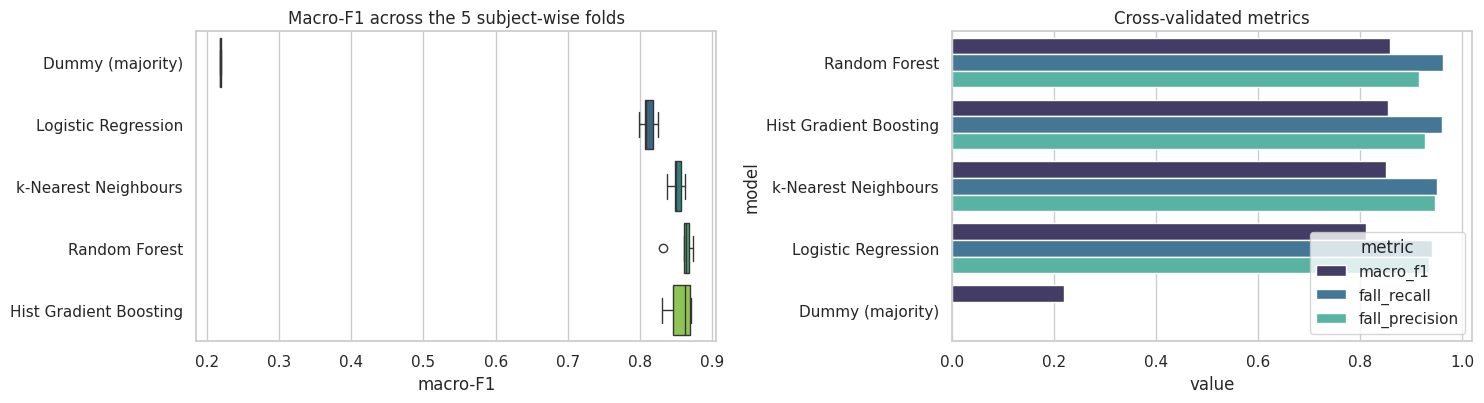

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
sns.boxplot(data=pd.DataFrame(fold_scores), orient="h", ax=axes[0], palette="viridis"); axes[0].set_title("Macro-F1 across the 5 subject-wise folds"); axes[0].set_xlabel("macro-F1")
m = cv_table.melt(id_vars="model", value_vars=["macro_f1", "fall_recall", "fall_precision"], var_name="metric")
sns.barplot(data=m, y="model", x="value", hue="metric", ax=axes[1], palette="mako"); axes[1].set_title("Cross-validated metrics"); axes[1].set_xlim(0, 1.02)
plt.tight_layout(); plt.show()

## 9. Hyper-parameter tuning
The two strongest tree ensembles are tuned with a randomized search, scored by macro-F1 under the same
subject-wise folds — so tuning can't overfit to particular people.

In [17]:
top2 = [n for n in cv_table.model if n in ("Random Forest", "Hist Gradient Boosting")][:2]
search_space = {
    "Random Forest": (RandomForestClassifier(class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_SEED),
                      {"n_estimators": [150, 250], "max_depth": [10, 16, None], "min_samples_leaf": [2, 3, 5], "max_features": ["sqrt", 0.5]}),
    "Hist Gradient Boosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_SEED),
                               {"learning_rate": [0.03, 0.06, 0.1, 0.2], "max_iter": [100, 150, 200], "max_leaf_nodes": [15, 31],
                                "min_samples_leaf": [10, 20, 50], "l2_regularization": [0.0, 0.1, 1.0]}),
}
tuned = {}
for name in top2:
    est, grid = search_space[name]
    s = RandomizedSearchCV(est, grid, n_iter=4, scoring="f1_macro", cv=GroupKFold(n_splits=3), random_state=RANDOM_SEED, n_jobs=1, refit=True)
    t0 = time.time(); s.fit(X_train, y_train, groups=g_train)
    tuned[name] = s
    print(f"{name:24s} best CV macro-F1 = {s.best_score_:.4f}   ({time.time()-t0:.0f}s)\n    {s.best_params_}")

Random Forest            best CV macro-F1 = 0.8609   (97s)
    {'n_estimators': 150, 'min_samples_leaf': 3, 'max_features': 'sqrt', 'max_depth': None}


Hist Gradient Boosting   best CV macro-F1 = 0.8569   (8s)
    {'min_samples_leaf': 10, 'max_leaf_nodes': 31, 'max_iter': 100, 'learning_rate': 0.2, 'l2_regularization': 1.0}


## 10. Best-model selection
The winner is the tuned model with the highest cross-validated macro-F1; ties are broken by **fall recall**
(safety first), then by simplicity.

In [18]:
rank = []
for name, s in tuned.items():
    r = cross_validate(s.best_estimator_, X_train, y_train, groups=g_train, cv=GroupKFold(n_splits=5), scoring=scoring, n_jobs=1)
    rank.append({"model": name + " (tuned)", **{k: r[f"test_{k}"].mean() for k in scoring}})
rank = pd.DataFrame(rank).sort_values(["macro_f1", "fall_recall"], ascending=False).reset_index(drop=True)
display(rank.round(4))
best_name = rank.loc[0, "model"].replace(" (tuned)", "")
best_est = tuned[best_name].best_estimator_
print("\n>>> selected model:", best_name)

,model,macro_f1,balanced_acc,fall_recall,fall_precision
0,Hist Gradient Boosting (tuned),0.8598,0.9037,0.9608,0.9278
1,Random Forest (tuned),0.8587,0.8816,0.9624,0.9159



>>> selected model: Hist Gradient Boosting


## 11. Probability calibration
The backend auto-triggers an SOS when `confidence ≥ 0.8`. That number is only meaningful if "0.8" really means
"right ~80% of the time". Tree ensembles are usually over/under-confident, so the selected model is wrapped in an
isotonic calibrator fitted with subject-wise folds, and we compare reliability before vs. after.

fall-probability  Brier  raw=0.0078  calibrated=0.0071
fall-probability  ECE    raw=0.0048  calibrated=0.0091


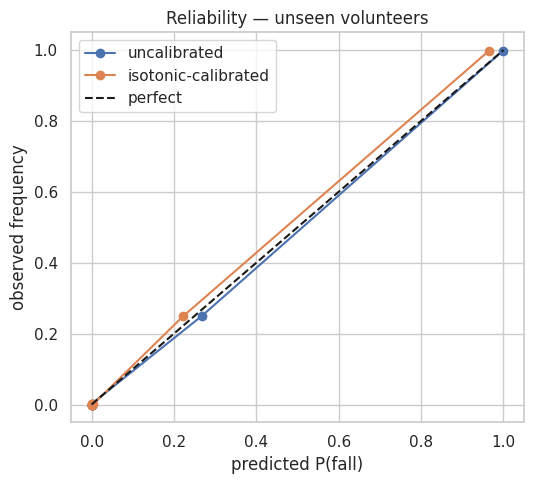

In [19]:
calib_splits = list(GroupKFold(n_splits=4).split(X_train, y_train, g_train))
calibrated = CalibratedClassifierCV(best_est, method="isotonic", cv=calib_splits)
calibrated.fit(X_train, y_train)

def expected_calibration_error(y_true_bin, p, bins=10):
    edges = np.linspace(0, 1, bins + 1); ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (p >= lo) & (p < hi if hi < 1 else p <= hi)
        if m.any():
            ece += m.mean() * abs(y_true_bin[m].mean() - p[m].mean())
    return ece

best_est.fit(X_train, y_train)
fall_idx_raw = list(best_est.classes_).index("sudden_fall"); fall_idx_cal = list(calibrated.classes_).index("sudden_fall")
yb = (y_test == "sudden_fall").astype(int)
p_raw, p_cal = best_est.predict_proba(X_test)[:, fall_idx_raw], calibrated.predict_proba(X_test)[:, fall_idx_cal]
print(f"fall-probability  Brier  raw={brier_score_loss(yb, p_raw):.4f}  calibrated={brier_score_loss(yb, p_cal):.4f}")
print(f"fall-probability  ECE    raw={expected_calibration_error(yb, p_raw):.4f}  calibrated={expected_calibration_error(yb, p_cal):.4f}")
plt.figure(figsize=(5.5, 5))
for p, lab in ((p_raw, "uncalibrated"), (p_cal, "isotonic-calibrated")):
    fr, mp = calibration_curve(yb, p, n_bins=10, strategy="quantile"); plt.plot(mp, fr, "o-", label=lab)
plt.plot([0, 1], [0, 1], "k--", label="perfect"); plt.xlabel("predicted P(fall)"); plt.ylabel("observed frequency"); plt.title("Reliability — unseen volunteers"); plt.legend(); plt.tight_layout(); plt.show()

## 12. Final evaluation on volunteers the model has never seen

               precision    recall  f1-score   support

       normal      0.980     0.978     0.979      5620
      running      0.881     0.952     0.915       500
abrupt_motion      0.642     0.567     0.602       180
  sudden_fall      0.972     0.961     0.966       900

     accuracy                          0.964      7200
    macro avg      0.869     0.864     0.866      7200
 weighted avg      0.963     0.964     0.963      7200

balanced accuracy: 0.8644 | macro-F1: 0.8656


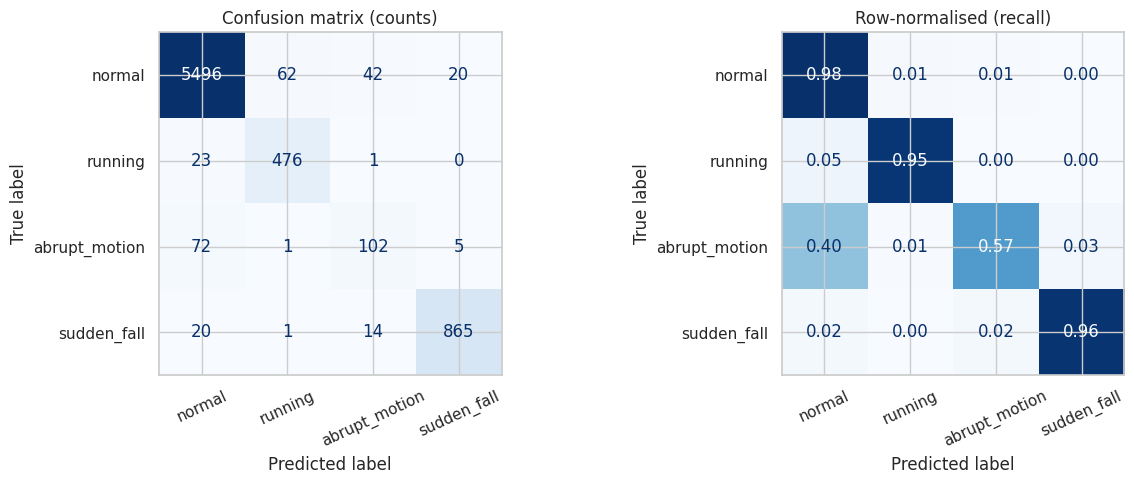

In [20]:
final_model = calibrated
proba = final_model.predict_proba(X_test)
classes = list(final_model.classes_)
y_pred = np.array(classes)[proba.argmax(1)]
print(classification_report(y_test, y_pred, labels=CLASS_LABELS, digits=3))
report = classification_report(y_test, y_pred, labels=CLASS_LABELS, output_dict=True)
print("balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4), "| macro-F1:", round(f1_score(y_test, y_pred, average="macro"), 4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=CLASS_LABELS), display_labels=CLASS_LABELS).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix (counts)"); axes[0].tick_params(axis="x", rotation=25)
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=CLASS_LABELS, normalize="true"), display_labels=CLASS_LABELS).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
axes[1].set_title("Row-normalised (recall)"); axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

At the backend threshold P(fall) ≥ 0.8: precision=0.996  recall=0.863  (TP=777, FP=3, FN=123)
false fall alerts on everyday walking/running windows: 2 of 6,120  -> ≈ 1.18 per hour of continuous activity (upper estimate; windows overlap)
abrupt (stumble/jump/collapse) windows wrongly flagged as fall at ≥0.8: 1 of 180


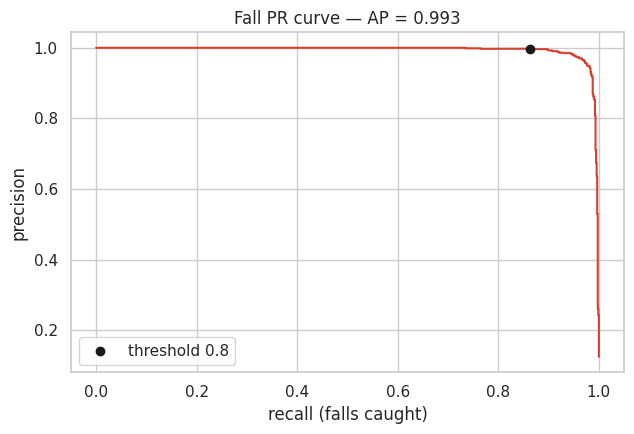

In [21]:
# Precision–recall for the safety-critical class and the operating point the backend uses (≥ 0.8)
prec, rec, thr = precision_recall_curve(yb, p_cal)
THRESHOLD = 0.8
pred_fall = p_cal >= THRESHOLD
tp = int((pred_fall & (yb == 1)).sum()); fp = int((pred_fall & (yb == 0)).sum()); fn = int((~pred_fall & (yb == 1)).sum())
print(f"At the backend threshold P(fall) ≥ {THRESHOLD}: precision={tp/max(tp+fp,1):.3f}  recall={tp/max(tp+fn,1):.3f}  (TP={tp}, FP={fp}, FN={fn})")
daily = np.isin(y_test, ["normal", "running"])
fp_daily = int((pred_fall & daily).sum())
print(f"false fall alerts on everyday walking/running windows: {fp_daily} of {daily.sum():,}  "
      f"-> ≈ {fp_daily/daily.sum()*3600:.2f} per hour of continuous activity (upper estimate; windows overlap)")
hard = y_test == "abrupt_motion"
print(f"abrupt (stumble/jump/collapse) windows wrongly flagged as fall at ≥{THRESHOLD}: {int((pred_fall & hard).sum())} of {hard.sum()}")
plt.figure(figsize=(6.5, 4.5)); plt.plot(rec, prec, color="#D6402F"); plt.scatter([tp/max(tp+fn,1)], [tp/max(tp+fp,1)], c="k", zorder=3, label=f"threshold {THRESHOLD}")
plt.xlabel("recall (falls caught)"); plt.ylabel("precision"); plt.title(f"Fall PR curve — AP = {average_precision_score(yb, p_cal):.3f}"); plt.legend(); plt.tight_layout(); plt.show()

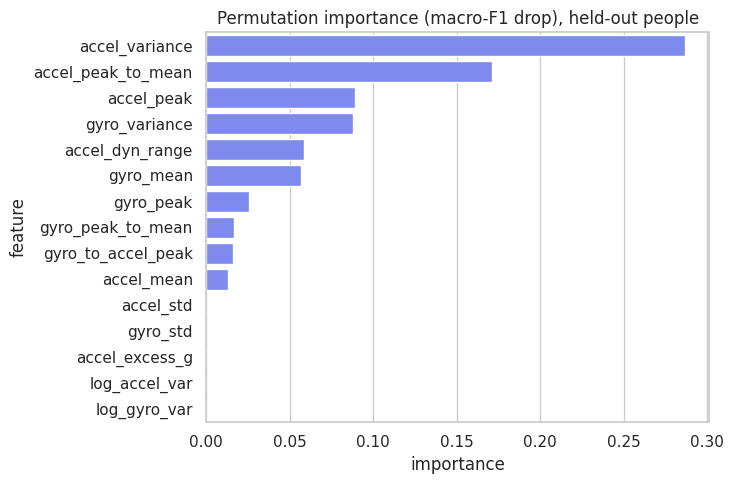

In [22]:
# Which features does the final model actually rely on? Permutation importance on unseen people.
pi = permutation_importance(final_model, X_test, y_test, scoring="f1_macro", n_repeats=8, random_state=RANDOM_SEED, n_jobs=1)
imp = pd.DataFrame({"feature": FEATURE_NAMES, "importance": pi.importances_mean, "std": pi.importances_std}).sort_values("importance", ascending=False)
plt.figure(figsize=(7.5, 5)); sns.barplot(data=imp, y="feature", x="importance", color="#6C7BFF"); plt.title("Permutation importance (macro-F1 drop), held-out people"); plt.tight_layout(); plt.show()

## 13. Robustness checks
Two things differ between this lab data and a phone in the real world. We measure how much it matters rather than assume.
1. **Sensor noise** — add Gaussian noise to the engineered inputs' sources (6 base stats) of increasing size.
2. **Different decimation** — what if the phone point-samples instead of low-pass filtering?

In [23]:
def macro_f1_on(df):
    X = engineer(df)[FEATURE_NAMES].to_numpy(); p = np.array(classes)[final_model.predict_proba(X).argmax(1)]
    return f1_score(df.label, p, average="macro"), recall_score(df.label, p, labels=["sudden_fall"], average="macro", zero_division=0)

base_test = test[["subject", "activity", "label", "phase"] + BASE_FEATURES]
rob = []
for noise in (0.0, 0.05, 0.10, 0.20, 0.30):
    noisy = base_test.copy()
    for f in BASE_FEATURES:
        noisy[f] = np.clip(noisy[f] * (1 + rng.normal(0, noise, len(noisy))), 0, None)
    f1m, fr = macro_f1_on(noisy); rob.append({"multiplicative noise σ": noise, "macro-F1": f1m, "fall recall": fr})
display(pd.DataFrame(rob).round(3))

# point-sampled (no anti-alias filter) variant of the held-out trials
alt = []
test_trials = [k for k in trials if k[0] in set(test.subject)]
for (subject, code, name) in test_trials:
    acc, gyro = trials[(subject, code, name)]
    a = np.linalg.norm(acc[::20], axis=1) * G; g = np.linalg.norm(gyro[::20], axis=1); n = min(len(a), len(g))
    starts = np.arange(0, n - WIN + 1, STRIDE); label = CLASS_OF[code]
    if label in ("sudden_fall", "abrupt_motion"):
        imp_i = int(np.argmax(np.linalg.norm(acc, axis=1))) // 20; starts = starts[(starts <= imp_i) & (imp_i < starts + WIN)]
    elif len(starts) > CAP_PER_FILE:
        starts = rng.choice(starts, CAP_PER_FILE, replace=False)
    if not len(starts): continue
    idx = starts[:, None] + np.arange(WIN)[None, :]
    am, ap, av = window_stats(a[idx]); gm, gp, gv = window_stats(g[idx])
    alt += [(subject, code, label, 0, am[k], ap[k], av[k], gm[k], gp[k], gv[k]) for k in range(len(starts))]
alt = pd.DataFrame(alt, columns=["subject", "activity", "label", "phase"] + BASE_FEATURES)
f1m, fr = macro_f1_on(alt)
print(f"point-sampled 10 Hz (no filter): macro-F1={f1m:.3f}  fall recall={fr:.3f}   vs. filtered: see report above")

,multiplicative noise σ,macro-F1,fall recall
0,0.00,0.866,0.961
1,0.05,0.821,0.947
2,0.10,0.780,0.918
3,0.20,0.665,0.829
4,0.30,0.585,0.719


point-sampled 10 Hz (no filter): macro-F1=0.686  fall recall=0.942   vs. filtered: see report above


## 14. Refit on all volunteers and export
Selection and evaluation are finished, so the chosen configuration is refit on **every** volunteer
(more people → better generalisation) and saved. The numbers in the metadata are the honest held-out ones from step 12.

In [24]:
X_all, y_all, g_all = data[FEATURE_NAMES].to_numpy(), data.label.to_numpy(), data.subject.to_numpy()
deploy_base = type(best_est)(**best_est.get_params())
deploy = CalibratedClassifierCV(deploy_base, method="isotonic", cv=list(GroupKFold(n_splits=4).split(X_all, y_all, g_all)))
deploy.fit(X_all, y_all)

joblib.dump(deploy, ARTIFACTS_DIR / "motion_classifier.pkl")
joblib.dump(deploy, ARTIFACTS_DIR / "motion_classifier.joblib")
metadata = {
    "model_name": f"{best_name} + isotonic calibration",
    "feature_names": FEATURE_NAMES,
    "base_features": BASE_FEATURES,
    "class_labels": list(deploy.classes_),
    "serving_map": {"abrupt_motion": "normal"},
    "trained_on": "SisFall (Sucerquia et al., Sensors 2017) — real accelerometer+gyroscope recordings",
    "dataset": {"source": "https://github.com/Fall-Prevention-Team/sisfallData", "subjects": len(SUBJECTS), "trials_used": len(trials),
                "windows": int(len(data)), "resampled_hz": APP_HZ, "window_s": WINDOW_S, "stride_s": STRIDE_S},
    "evaluation": {"protocol": "5 unseen volunteers (GroupShuffleSplit); CV is GroupKFold by volunteer",
                   "test_accuracy": float(report["accuracy"]), "test_macro_f1": float(f1_score(y_test, y_pred, average="macro")),
                   "test_balanced_accuracy": float(balanced_accuracy_score(y_test, y_pred)),
                   "per_class_f1": {c: float(report[c]["f1-score"]) for c in CLASS_LABELS},
                   "fall_recall_at_0.8": float(tp / max(tp + fn, 1)), "fall_precision_at_0.8": float(tp / max(tp + fp, 1)),
                   "cv_macro_f1_by_model": {r["model"]: float(r["macro_f1"]) for r in results}},
    "sklearn_version": sklearn.__version__, "numpy_version": np.__version__,
    "limitations": ["Sensor worn at waist in SisFall; phones are hand/pocket/bag carried (magnitude features are orientation-free but placement still matters).",
                    "No public data for phone-snatch or struggle: those event types are heuristic + log-only in the service.",
                    "SisFall volunteers are 19-30 y/o adults for the falls; re-validate with your own labelled app data."],
}
(ARTIFACTS_DIR / "motion_classifier_metadata.json").write_text(json.dumps(metadata, indent=2))
data[["subject", "activity", "label"] + FEATURE_NAMES].to_csv(DATA_DIR / "motion_features_sisfall.csv", index=False)
print("saved:", *(p.name for p in ARTIFACTS_DIR.glob("motion_classifier*")), "+ data/motion_features_sisfall.csv")

saved: motion_classifier.joblib motion_classifier.pkl motion_classifier_metadata.json + data/motion_features_sisfall.csv


## 15. Serving-contract test
Load the artifact **exactly as `motion_classifier_service.py` does** and classify windows built from raw summary
statistics — the same six numbers the mobile app posts.

In [25]:
loaded = joblib.load(ARTIFACTS_DIR / "motion_classifier.pkl")
meta = json.loads((ARTIFACTS_DIR / "motion_classifier_metadata.json").read_text())

def serve(accel, gyro):
    df = pd.DataFrame([{"accel_mean": accel[0], "accel_peak": accel[1], "accel_variance": accel[2],
                        "gyro_mean": gyro[0], "gyro_peak": gyro[1], "gyro_variance": gyro[2]}])
    X = engineer(df)[meta["feature_names"]].to_numpy()
    p = loaded.predict_proba(X)[0]
    return {k: float(v) for k, v in sorted(zip(loaded.classes_, p.round(3)), key=lambda kv: -kv[1])}

print("phone resting      :", serve((9.8, 9.9, 0.001), (0.01, 0.03, 0.0)))
print("brisk walk         :", serve((10.3, 14.5, 2.0), (0.35, 1.0, 0.07)))
print("hard impact + spin :", serve((14.0, 47.0, 70.0), (2.2, 6.0, 2.5)))

phone resting      : {'normal': 0.998, 'sudden_fall': 0.001, 'abrupt_motion': 0.0, 'running': 0.0}
brisk walk         : {'normal': 0.948, 'abrupt_motion': 0.051, 'running': 0.001, 'sudden_fall': 0.0}
hard impact + spin : {'sudden_fall': 0.908, 'running': 0.091, 'abrupt_motion': 0.0, 'normal': 0.0}


## 16. Conclusions & next steps
* Trained and evaluated on **real** recordings, validated on **people the model never saw** — the number to quote
  is the held-out table in section 12, not a random-split accuracy.
* Probabilities are **calibrated**, so the backend's `≥ 0.8` auto-SOS threshold has a defensible meaning.
* Stumbles/jumps/collapses are modelled explicitly so they are not mistaken for falls.
* **Gaps to close with your own data:** (1) phone placement (hand/pocket/bag), (2) women-specific and Indian-population
  gait, (3) phone-snatch and struggle events. The app already stores every classified window in `SensorLog`; after
  a consented pilot, export those rows, label them and re-run this notebook with one extra class.